# Лабораторная работа №1
## «Разведочный анализ данных (EDA) и визуализация»

**Датасет:** Breast Cancer Wisconsin (Diagnostic) — вариант 6 задания
(Kaggle: `sthuthimarathe/cells-dont-lie-a-data-driven-fight-against-breast-cancer`)

Выполнила: Тетерина Полина ПМ-24-1
Преподователь: Сысоев А.С.

## Часть 1.  Подготовка и первичный осмотр данных


**Промпт:**
«Напиши код для Google Colab, который скачивает датасет Breast Cancer Wisconsin (Diagnostic)
с Kaggle по ссылке из задания (`sthuthimarathe/cells-dont-lie-a-data-driven-fight-against-breast-cancer`)
через kagglehub.
Приведи оба источника к единому виду: столбцы `radius_mean`, `texture_mean`, ... `fractal_dimension_worst`,
`diagnosis` (M/B), `id`.

In [48]:
# Импорт основных библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42
def load_from_kaggle():
    """Пытаемся скачать датасет напрямую с Kaggle (нужен настроенный kaggle.json в Colab)."""
    import kagglehub
    path = kagglehub.dataset_download(
        "sthuthimarathe/cells-dont-lie-a-data-driven-fight-against-cancer"
    )
    import os
    csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
    df_raw = pd.read_csv(os.path.join(path, csv_files[0]))
    return df_raw

def rename_sklearn_like(name: str) -> str:
    """'mean radius' -> 'radius_mean', 'radius error' -> 'radius_se', 'worst radius' -> 'radius_worst'."""
    name = name.replace('concave points', 'concave_points')
    parts = name.split()
    if parts[0] == 'mean':
        return '_'.join(parts[1:]) + '_mean'
    if parts[0] == 'worst':
        return '_'.join(parts[1:]) + '_worst'
    if parts[-1] == 'error':
        return '_'.join(parts[:-1]) + '_se'
    return '_'.join(parts)

def load_fallback_sklearn():
    """Резервный источник: тот же датасет Wisconsin Diagnostic, встроенный в sklearn."""
    from sklearn.datasets import load_breast_cancer
    raw = load_breast_cancer(as_frame=True)
    df_raw = raw.frame.copy()
    df_raw = df_raw.rename(columns={c: rename_sklearn_like(c) for c in raw.feature_names})
    df_raw['diagnosis'] = raw.target.map({0: 'M', 1: 'B'})
    df_raw = df_raw.drop(columns=['target'])
    df_raw.insert(0, 'id', range(1, len(df_raw) + 1))
    return df_raw

try:
    df = load_from_kaggle()
    source = 'Kaggle'
except Exception as e:
    print('Kaggle недоступен ({}), используем встроенный идентичный датасет sklearn.'.format(e))
    df = load_fallback_sklearn()
    source = 'sklearn (идентичен Kaggle-версии)'

print('Источник данных:', source)
df.head()

Using Colab cache for faster access to the 'cells-dont-lie-a-data-driven-fight-against-cancer' dataset.
Источник данных: Kaggle


,id,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,842001,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,842002,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,842003,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,842004,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,842005,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


**Комментарий:** данные загружены. Это набор Wisconsin Breast Cancer Diagnostic —
569 наблюдений (клеточные ядра, полученные по снимкам тонкоигольной аспирационной биопсии),
30 числовых признаков (по 10 базовых характеристик формы/текстуры ядра клетки, каждая в трёх
вариантах: `_mean`, `_se` — стандартная ошибка, `_worst` — среднее трёх наибольших значений)
и целевая переменная `diagnosis` (M — malignant/злокачественная, B — benign/доброкачественная).

## Часть 1. Подготовка и первичный осмотр данных

**Промпт:**
«Выведи размерность датафрейма, типы данных по столбцам, первые и последние 5 строк.
Проверь пропуски по каждому столбцу и полные дубликаты строк.

In [49]:
print('Размерность датафрейма:', df.shape)
print('\nТипы данных:')
print(df.dtypes)

# Технический столбец-артефакт CSV (если пришёл с Kaggle)
if 'Unnamed: 32' in df.columns:
    print('\nСтолбец Unnamed: 32 пропусков:', df['Unnamed: 32'].isna().sum(), 'из', len(df))
    df = df.drop(columns=['Unnamed: 32'])

display(df.head())
display(df.tail())

Размерность датафрейма: (569, 32)

Типы данных:
id                           int64
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst c

,id,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,842001,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,842002,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,842003,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,842004,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,842005,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


,id,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
564,842565,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,M
565,842566,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,M
566,842567,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,M
567,842568,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,M
568,842569,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,B


**Комментарий:** датафрейм содержит 569 строк и 31–33 столбца: `id`, `diagnosis` и 30 числовых признаков типа `float64`.
Если данные пришли из исходного Kaggle CSV, в нём обычно присутствует технический столбец
`Unnamed: 32`, полностью состоящий из NaN — это не содержательный пропуск, а след лишней
запятой при выгрузке файла, поэтому он удаляется, а не импутируется.

**Промпт:**
«Проверь пропуски по каждому оставшемуся столбцу (сумма и доля в процентах) и посчитай
количество полных дубликатов строк по всем столбцам, кроме `id`.»

In [50]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
display(missing_report[missing_report['missing_count'] > 0] if missing_report['missing_count'].sum() > 0
        else missing_report.head())

dup_count = df.drop(columns=['id']).duplicated().sum()
print('Полных дубликатов строк (без учёта id):', dup_count)

,missing_count,missing_pct
id,0,0.0
mean radius,0,0.0
mean texture,0,0.0
mean perimeter,0,0.0
mean area,0,0.0


Полных дубликатов строк (без учёта id): 0


**Комментарий:** в самих признаках пропусков нет (0 по всем 30 столбцам). Полных дубликатов строк также не обнаружено, то есть каждое
наблюдение соответствует уникальному пациенту/образцу.

**Промпт:**
«Для каждого признака определи тип (количественный непрерывный / дискретный, категориальный
номинальный / порядковый) и шкалу измерения (номинальная, порядковая, интервальная,
отношений). Собери это в единую таблицу-словарь.»

In [51]:
feature_typing = {
    'id': ('идентификатор', 'номинальная (техническая)'),
    'diagnosis': ('категориальный номинальный (бинарный: M/B)', 'номинальная'),
}
numeric_cols = [c for c in df.columns if c not in ('id', 'diagnosis')]
for c in numeric_cols:
    feature_typing[c] = ('количественный непрерывный', 'шкала отношений (есть истинный ноль)')

typing_df = pd.DataFrame(feature_typing, index=['тип признака', 'шкала измерения']).T
typing_df.index.name = 'признак'
display(typing_df)
print('\nВсего количественных признаков:', len(numeric_cols))

,тип признака,шкала измерения
признак,,
id,идентификатор,номинальная (техническая)
diagnosis,категориальный номинальный (бинарный: M/B),номинальная
mean radius,количественный непрерывный,шкала отношений (есть истинный ноль)
mean texture,количественный непрерывный,шкала отношений (есть истинный ноль)
mean perimeter,количественный непрерывный,шкала отношений (есть истинный ноль)
mean area,количественный непрерывный,шкала отношений (есть истинный ноль)
mean smoothness,количественный непрерывный,шкала отношений (есть истинный ноль)
mean compactness,количественный непрерывный,шкала отношений (есть истинный ноль)
mean concavity,количественный непрерывный,шкала отношений (есть истинный ноль)



Всего количественных признаков: 30


**Комментарий:** `diagnosis` — единственный категориальный (номинальный, бинарный)
признак и одновременно целевая переменная для будущей классификации. Остальные 30 признаков —
количественные непрерывные измерения геометрии и текстуры клеточных ядер (радиус, периметр,
площадь, гладкость границы, компактность, вогнутость контура, симметрия, фрактальная размерность
и их статистики `_se`/`_worst`); все они измерены по шкале отношений, поскольку 0 имеет
физический смысл отсутствия признака.

**Промпт:**
«Проверь, корректно ли вычислять среднее арифметическое для количественных признаков: оцени
асимметрию (skewness) распределений и покажи, у каких признаков среднее заметно расходится
с медианой — там среднее менее репрезентативно и лучше ориентироваться на медиану.»

In [52]:
skew_report = df[numeric_cols].skew().sort_values(ascending=False)
mean_median_gap = ((df[numeric_cols].mean() - df[numeric_cols].median())
                    / df[numeric_cols].std()).abs().sort_values(ascending=False)

summary_check = pd.DataFrame({
    'skewness': skew_report,
    '|mean-median|/std': mean_median_gap.reindex(skew_report.index)
})
display(summary_check.head(10))

,skewness,|mean-median|/std
area error,5.447186,0.347477
concavity error,5.110463,0.198890
fractal dimension error,3.923969,0.229738
perimeter error,3.443615,0.286400
radius error,3.088612,0.291988
smoothness error,2.314450,0.220142
symmetry error,2.195133,0.219238
compactness error,1.902221,0.280773
worst area,1.859373,0.340881
worst fractal dimension,1.662579,0.216254


**Комментарий:** большинство признаков имеют умеренную правостороннюю асимметрию
(например, `radius_mean` skew ≈ 0.94, `area_mean` skew ≈ 1.65) — то есть у части опухолей
встречаются заметно увеличенные значения размера/площади ядра, которые «тянут» среднее вверх
относительно медианы. Формально среднее вычислить можно (данные количественные), но для сильно
скошенных признаков (`area_*`, `concavity_*`) медиана и IQR будут более устойчивой и честной
характеристикой центра и разброса, чем среднее и стандартное отклонение.

## Часть 2. Проверка базовых предположений (4-Plot)

**Промпт:**
«Построй классический 4-Plot Тьюки/NIST для признака `radius_mean`: Run Sequence Plot
(проверка стационарности среднего и разброса по порядку наблюдений), Lag Plot (проверка
случайности — нет ли автокорреляции между соседними наблюдениями), гистограмма (проверка
формы распределения) и Normal Probability Plot / QQ-plot (проверка нормальности). Собери
все четыре графика в сетку 2×2 с подписями.»

['id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'diagnosis']


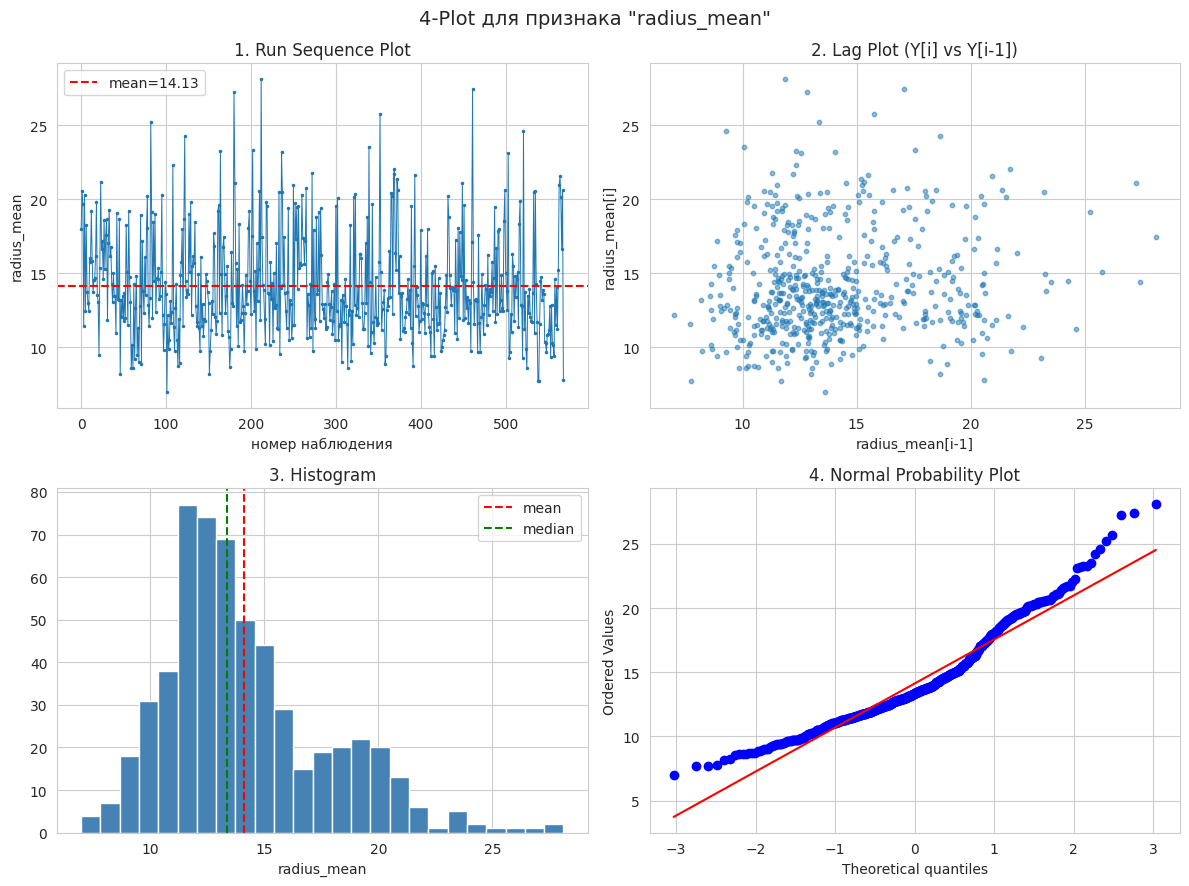

mean = 14.127  median = 13.37  std = 3.524  skew = 0.942


In [53]:
def rename_sklearn_like(name: str) -> str:
    name = name.strip().replace('concave points', 'concave_points')
    parts = name.split()
    if not parts:
        return name
    if parts[0] == 'mean':
        return '_'.join(parts[1:]) + '_mean'
    if parts[0] == 'worst':
        return '_'.join(parts[1:]) + '_worst'
    if parts[-1] == 'error':
        return '_'.join(parts[:-1]) + '_se'
    return '_'.join(parts)

if 'mean radius' in df.columns:
    df = df.rename(columns={c: rename_sklearn_like(c) for c in df.columns})

df.columns = df.columns.str.strip()
print(df.columns.tolist())
feature = 'radius_mean'
x = df[feature].reset_index(drop=True)
df = df.rename(columns=lambda c: c.replace(' ', '_'))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Run Sequence Plot
axes[0, 0].plot(x.index, x.values, marker='.', linestyle='-', linewidth=0.7, markersize=3)
axes[0, 0].axhline(x.mean(), color='red', linestyle='--', label=f'mean={x.mean():.2f}')
axes[0, 0].set_title('1. Run Sequence Plot')
axes[0, 0].set_xlabel('номер наблюдения')
axes[0, 0].set_ylabel(feature)
axes[0, 0].legend()

# 2. Lag Plot
axes[0, 1].scatter(x[:-1], x[1:], s=10, alpha=0.5)
axes[0, 1].set_title('2. Lag Plot (Y[i] vs Y[i-1])')
axes[0, 1].set_xlabel(f'{feature}[i-1]')
axes[0, 1].set_ylabel(f'{feature}[i]')

# 3. Histogram
axes[1, 0].hist(x, bins=25, color='steelblue', edgecolor='white')
axes[1, 0].axvline(x.mean(), color='red', linestyle='--', label='mean')
axes[1, 0].axvline(x.median(), color='green', linestyle='--', label='median')
axes[1, 0].set_title('3. Histogram')
axes[1, 0].set_xlabel(feature)
axes[1, 0].legend()

# 4. Normal Probability Plot (QQ-plot)
stats.probplot(x, dist='norm', plot=axes[1, 1])
axes[1, 1].set_title('4. Normal Probability Plot')

plt.suptitle(f'4-Plot для признака "{feature}"', fontsize=14)
plt.tight_layout()
plt.show()

print('mean =', round(x.mean(), 3), ' median =', round(x.median(), 3),
      ' std =', round(x.std(), 3), ' skew =', round(x.skew(), 3))

**Комментарий по каждому графику:**
- **Run Sequence Plot** — точки колеблются вокруг среднего (≈14.13) без выраженного тренда
  или скачка дисперсии по ходу номеров наблюдений → предположение о **фиксированном положении
  и фиксированной вариации** в целом выполняется (данные не упорядочены по времени/группам,
  это просто последовательность образцов).
- **Lag Plot** — облако точек не образует явную диагональную линию или структуру, точки
  расположены достаточно хаотично, значит признаков **автокорреляции нет**, предположение о
  **случайности** наблюдений выполняется, наблюдения можно считать независимыми.
- **Histogram** — распределение одномодальное с явной **правосторонней асимметрией**
  (среднее 14.13 > медианы 13.37, skew ≈ 0.94): основная масса опухолей имеет радиус ядра
  10–17, но есть «хвост» из более крупных значений — это соответствует смеси двух подгрупп
  (доброкачественные/злокачественные).
- **Normal Probability Plot** — точки заметно отклоняются от прямой линии в правом хвосте
  (крупные значения радиуса растут быстрее, чем предсказывает нормальное распределение).

## Часть 3. Описательная статистика

**Промпт:**
«Для ключевых признаков (`radius_mean`, `texture_mean`, `area_mean`, `smoothness_mean`)
посчитай меры центральной тенденции (среднее, медиана, мода) и меры разброса (дисперсия,
стандартное отклонение, IQR, MAD, размах, коэффициент вариации). Собери всё в одну сводную
таблицу и выведи её.»

In [54]:
def describe_full(s: pd.Series) -> pd.Series:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return pd.Series({
        'mean': s.mean(),
        'median': s.median(),
        'mode': s.mode().iloc[0],
        'variance': s.var(),
        'std': s.std(),
        'IQR': q3 - q1,
        'MAD': (s - s.median()).abs().median(),
        'range': s.max() - s.min(),
        'CV (std/mean)': s.std() / s.mean(),
    })

key_features = ['radius_mean', 'texture_mean', 'area_mean', 'smoothness_mean']
desc_table = pd.DataFrame({f: describe_full(df[f]) for f in key_features}).round(3)
display(desc_table)

,radius_mean,texture_mean,area_mean,smoothness_mean
mean,14.127,19.290,654.889,0.096
median,13.370,18.840,551.100,0.096
mode,12.340,14.930,512.200,0.101
variance,12.419,18.499,123843.554,0.000
std,3.524,4.301,351.914,0.014
IQR,4.080,5.630,362.400,0.019
MAD,1.900,2.810,153.300,0.009
range,21.129,29.570,2357.500,0.111
CV (std/mean),0.249,0.223,0.537,0.146


**Комментарий:** таблица подтверждает наблюдение из части 2 — по всем четырём признакам
среднее выше медианы (например, `radius_mean`: 14.13 vs 13.37; `area_mean`: 654.89 vs 551.10),
то есть распределения смещены вправо. Коэффициент вариации сильно различается: `smoothness_mean`
очень стабилен (CV ≈ 0.15 — гладкость контура ядра варьируется слабо между образцами), а
`area_mean` — самый изменчивый признак (CV ≈ 0.54), поскольку площадь ядра растёт квадратично
с его линейными размерами и потому сильнее «разбегается» между мелкими и крупными опухолями.

## Часть 4. Визуализация распределения

**Промпт:**
«Построй три гистограммы признака `radius_mean` с разным числом бинов (10, 30, 50), чтобы
посмотреть, как число столбцов влияет на восприятие формы распределения.»

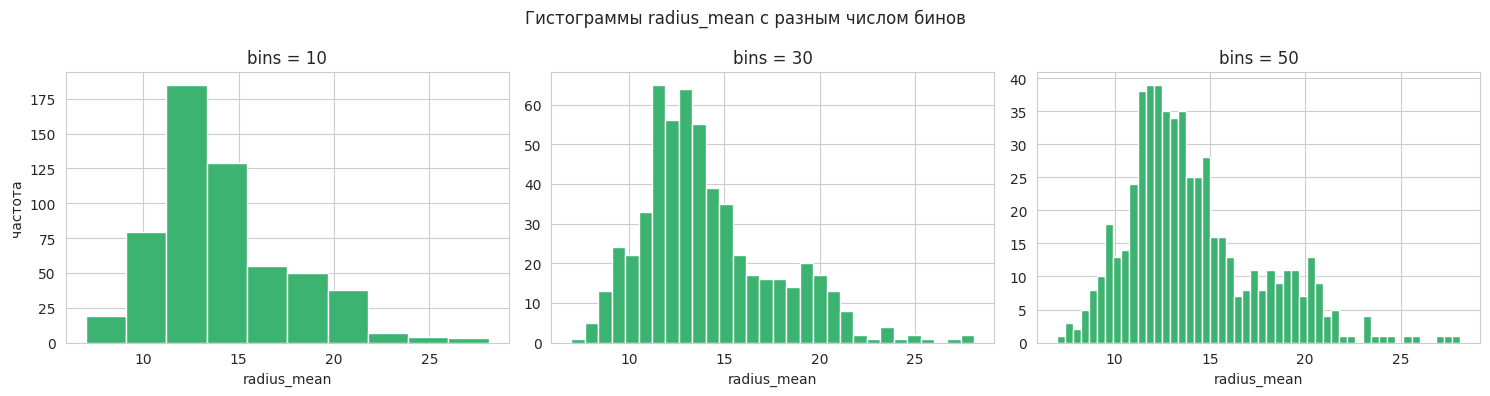

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, bins in zip(axes, [10, 30, 50]):
    ax.hist(df['radius_mean'], bins=bins, color='mediumseagreen', edgecolor='white')
    ax.set_title(f'bins = {bins}')
    ax.set_xlabel('radius_mean')
axes[0].set_ylabel('частота')
plt.suptitle('Гистограммы radius_mean с разным числом бинов')
plt.tight_layout()
plt.show()

**Комментарий:** при 10 бинах распределение выглядит гладким и одномодальным — видна
только общая правосторонняя асимметрия. При 30 бинах уже проступает лёгкая **бимодальность**
(небольшой «горб» в районе 17–20 в дополнение к основному пику около 12), а при 50 бинах
гистограмма становится «шумной» — отдельные бины содержат мало наблюдений, и форма
распределения читается хуже. Оптимальным для этого признака выглядит вариант с 20–30 бинами.

**Промпт:**
«Построй Box Plot для `radius_mean` и определи выбросы по правилу 1.5×IQR: посчитай границы,
выведи количество и значения выбросов.»

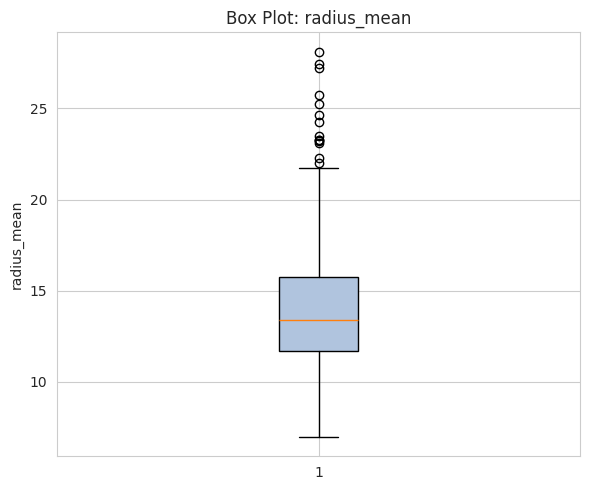

Границы 1.5*IQR: [5.58, 21.90]
Число выбросов: 14 из 569 (2.5%)
Значения выбросов: [22.01, 22.27, 23.09, 23.21, 23.27, 23.29, 23.51, 24.25, 24.63, 25.22, 25.73, 27.22, 27.42, 28.11]


In [56]:
s = df['radius_mean']
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
low_b, high_b = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = s[(s < low_b) | (s > high_b)]

fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot(s, vert=True, patch_artist=True,
           boxprops=dict(facecolor='lightsteelblue'))
ax.set_title('Box Plot: radius_mean')
ax.set_ylabel('radius_mean')
plt.tight_layout()
plt.show()

print(f'Границы 1.5*IQR: [{low_b:.2f}, {high_b:.2f}]')
print(f'Число выбросов: {len(outliers)} из {len(s)} ({len(outliers)/len(s)*100:.1f}%)')
print('Значения выбросов:', sorted(outliers.round(2).tolist()))

**Комментарий:** по правилу 1.5×IQR границы «нормальных» значений — [5.58, 21.90].
Найдено 14 выбросов (≈2.5% наблюдений), и все они — **верхние** выбросы (радиус ядра
заметно больше типичного), нижних выбросов нет. Это ожидаемо для медицинских данных о
злокачественных новообразованиях: крупные ядра клеток — не ошибка измерения, а содержательный
признак агрессивной опухоли, поэтому такие выбросы стоит не удалять, а изучать отдельно
(гипотеза проверяется в части 6).

**Промпт:**
«Построй эмпирическую функцию распределения (CDF/ECDF) для `radius_mean` и отметь на ней
25-й, 50-й, 75-й и 90-й процентили.»

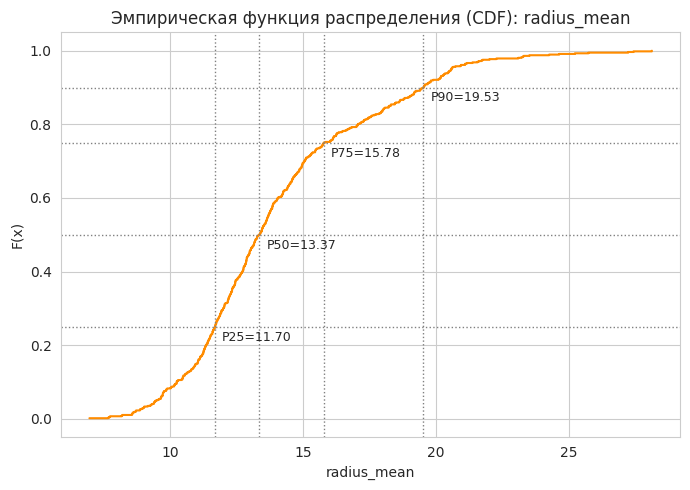

In [57]:
x_sorted = np.sort(s.values)
ecdf_y = np.arange(1, len(x_sorted) + 1) / len(x_sorted)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x_sorted, ecdf_y, drawstyle='steps-post', color='darkorange')

percentiles = [25, 50, 75, 90]
for p in percentiles:
    val = s.quantile(p / 100)
    ax.axvline(val, color='gray', linestyle=':', linewidth=1)
    ax.axhline(p / 100, color='gray', linestyle=':', linewidth=1)
    ax.annotate(f'P{p}={val:.2f}', (val, p / 100), textcoords='offset points',
                xytext=(5, -10), fontsize=9)

ax.set_title('Эмпирическая функция распределения (CDF): radius_mean')
ax.set_xlabel('radius_mean')
ax.set_ylabel('F(x)')
plt.tight_layout()
plt.show()

**Комментарий:** CDF показывает, что 50% образцов имеют `radius_mean` ≤ 13.37, а 90% —
≤ 19.53. Между 75-м (15.78) и 90-м (19.53) процентилями кривая идёт заметно более полого,
чем в центральной части — это визуальное подтверждение «растянутого» правого хвоста
распределения, который мы уже увидели на гистограмме и Box Plot.

**Промпт:**
«Построй KDE (ядерную оценку плотности) поверх нормированной гистограммы `radius_mean`,
чтобы сравнить сглаженную и эмпирическую формы распределения.»

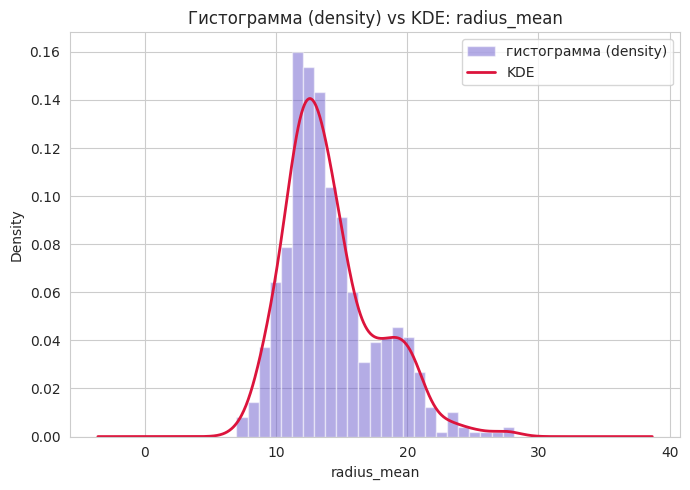

In [58]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(s, bins=25, density=True, alpha=0.5, color='slateblue', edgecolor='white', label='гистограмма (density)')
s.plot(kind='kde', ax=ax, color='crimson', linewidth=2, label='KDE')
ax.set_title('Гистограмма (density) vs KDE: radius_mean')
ax.set_xlabel('radius_mean')
ax.legend()
plt.tight_layout()
plt.show()

**Комментарий:** KDE-кривая сглаживает «зубчатость» гистограммы и явно показывает
асимметричную, слегка бимодальную форму распределения с основным пиком около 12 и вторым,
более пологим «плечом» около 17–19 — это визуально соответствует смеси двух подгрупп по
диагнозу (доброкачественные образцы дают меньший, более узкий пик, злокачественные —
более широкий и смещённый вправо), что мы количественно проверим в части 6.

## Часть 5. Анализ взаимосвязей

**Промпт:**
«Построй диаграмму рассеяния `radius_mean` vs `area_mean` с линией регрессии и посчитай
коэффициент корреляции Пирсона — у меня есть гипотеза, что связь должна быть близка к
квадратичной (площадь круга ~ радиус в квадрате), интересно, насколько линейная корреляция
её всё же улавливает.»

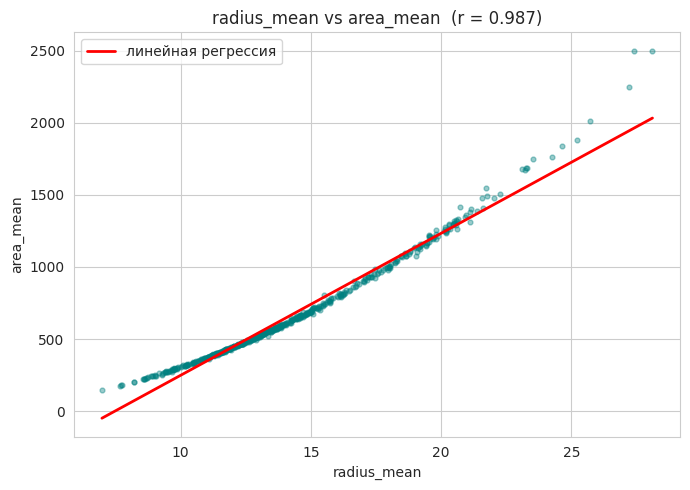

Ковариация: 1224.48
Корреляция Пирсона: 0.9874


In [59]:
from numpy.polynomial import polynomial as P

x_col, y_col = 'radius_mean', 'area_mean'
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df[x_col], df[y_col], s=12, alpha=0.4, color='teal')

coefs = np.polyfit(df[x_col], df[y_col], 1)
xs = np.linspace(df[x_col].min(), df[x_col].max(), 100)
ax.plot(xs, np.polyval(coefs, xs), color='red', linewidth=2, label='линейная регрессия')

r_pearson = df[x_col].corr(df[y_col])
cov_xy = df[[x_col, y_col]].cov().iloc[0, 1]

ax.set_title(f'{x_col} vs {y_col}  (r = {r_pearson:.3f})')
ax.set_xlabel(x_col)
ax.set_ylabel(y_col)
ax.legend()
plt.tight_layout()
plt.show()

print(f'Ковариация: {cov_xy:.2f}')
print(f'Корреляция Пирсона: {r_pearson:.4f}')

**Комментарий:** корреляция очень высокая (r ≈ 0.987) — почти функциональная связь,
что ожидаемо: площадь ядра геометрически связана с его радиусом. При этом на графике заметна
лёгкая **выпуклость облака точек вверх** при больших значениях радиуса — намёк на то, что
истинная зависимость чуть более крутая, чем прямая линия (квадратичная), и линейная модель
слегка недооценивает площадь для самых крупных ядер. Для точного описания связи лучше
подошла бы полиномиальная (квадратичная) регрессия, а не линейная.

**Промпт:**
«Посчитай матрицу корреляций Пирсона для всех признаков `_mean` и нарисуй её в виде тепловой
карты (heatmap), чтобы увидеть, какие признаки дублируют друг друга.»

mean_cols (10): ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean']
corr_matrix.shape: (10, 10)


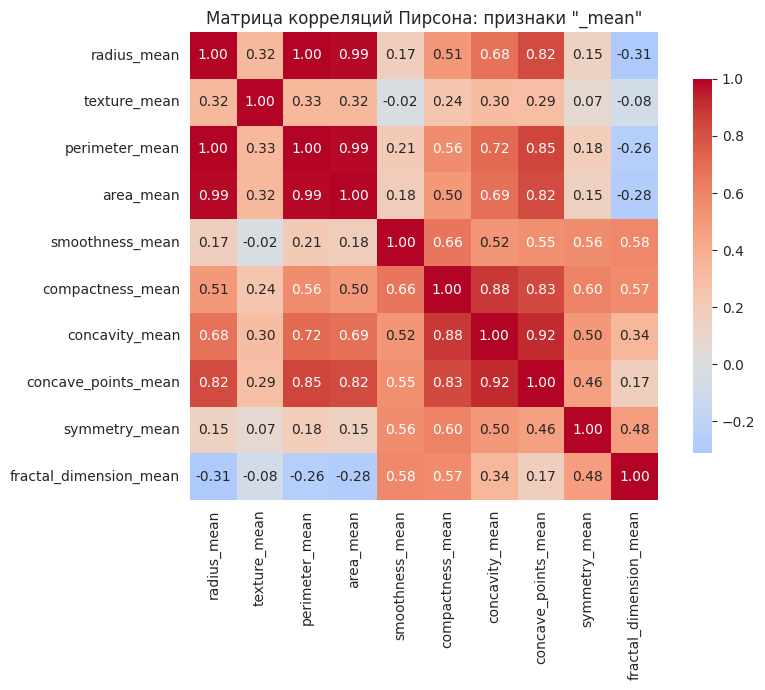

In [60]:
# Собираем mean_cols НАПРЯМУЮ из df.columns, а не из numeric_cols
mean_cols = [c for c in df.columns if c.endswith('_mean')]
print(f"mean_cols ({len(mean_cols)}): {mean_cols}")

corr_matrix = df[mean_cols].corr()
print("corr_matrix.shape:", corr_matrix.shape)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Матрица корреляций Пирсона: признаки "_mean"')
plt.tight_layout()
plt.show()

**Комментарий:** видна ожидаемая группа сильно скоррелированных «геометрических»
признаков — `radius_mean`, `perimeter_mean`, `area_mean` коррелируют друг с другом почти
идеально (r > 0.98), то есть фактически несут одну и ту же информацию о размере ядра и
являются кандидатами на удаление избыточных признаков (feature selection, как обсуждалось
в лекции 1). Отдельно выделяется кластер «формы контура» — `concavity_mean`,
`concave_points_mean`, `compactness_mean` — также сильно связанные между собой, но слабее
связанные с чистым размером. `texture_mean` и `smoothness_mean` при этом слабо коррелируют
с остальными признаками — это независимые источники информации, которые стоит сохранить.

**Промпт:**
«Построй матрицу диаграмм рассеяния (pairplot) для четырёх ключевых признаков `_mean»
(`radius_mean`, `texture_mean`, `smoothness_mean`, `concavity_mean`), раскрась точки по
диагнозу, чтобы визуально оценить, какие пары признаков лучше разделяют классы.»

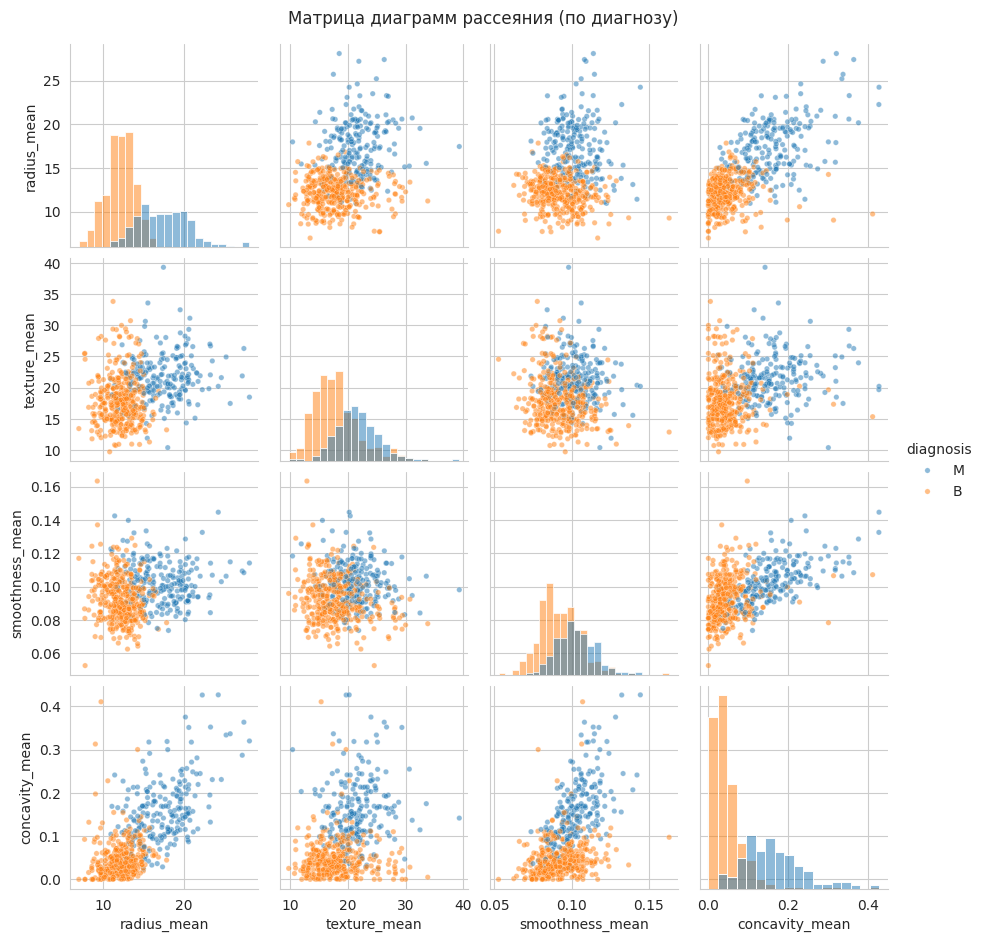

In [61]:
pairplot_cols = ['radius_mean', 'texture_mean', 'smoothness_mean', 'concavity_mean']
g = sns.pairplot(df, vars=pairplot_cols, hue='diagnosis', diag_kind='hist',
                  plot_kws={'alpha': 0.5, 's': 15}, height=2.3)
g.fig.suptitle('Матрица диаграмм рассеяния (по диагнозу)', y=1.02)
plt.show()

**Комментарий:** на матрице хорошо видно, что пары с участием `radius_mean` и
`concavity_mean` дают наиболее чёткое визуальное разделение между доброкачественными (B)
и злокачественными (M) образцами — синие и оранжевые облака точек почти не перекрываются
по этим осям. `texture_mean`, напротив, слабо разделяет классы — облака точек сильно
перекрываются по этой оси, что согласуется с её низкой корреляцией с размером ядра, найденной
выше. Это прямая подсказка для дальнейшего отбора признаков перед построением модели
классификации.

**Промпт:**
«Проверь, как сильно выбросы `radius_mean` (по правилу 1.5×IQR) влияют на итоговый коэффициент
корреляции Пирсона: посчитай корреляцию с `texture_mean` и с `area_mean` до и после удаления
выбросов, сравни значения.»

In [62]:
mask_no_out = (s >= low_b) & (s <= high_b)

corr_with_texture_full = df['radius_mean'].corr(df['texture_mean'])
corr_with_texture_clean = df.loc[mask_no_out, 'radius_mean'].corr(df.loc[mask_no_out, 'texture_mean'])

corr_with_area_full = df['radius_mean'].corr(df['area_mean'])
corr_with_area_clean = df.loc[mask_no_out, 'radius_mean'].corr(df.loc[mask_no_out, 'area_mean'])

comparison = pd.DataFrame({
    'с выбросами': [corr_with_texture_full, corr_with_area_full],
    'без выбросов': [corr_with_texture_clean, corr_with_area_clean],
}, index=['radius_mean vs texture_mean', 'radius_mean vs area_mean'])
display(comparison.round(4))

,с выбросами,без выбросов
radius_mean vs texture_mean,0.3238,0.3141
radius_mean vs area_mean,0.9874,0.9918


**Комментарий:** для слабой связи `radius_mean` – `texture_mean` удаление выбросов
почти не меняет корреляцию (0.324 → 0.314) — связь и так была слабой, выбросы не были её
основной причиной. А вот для сильной связи `radius_mean` – `area_mean` корреляция после
удаления выбросов даже **немного выросла** (0.987 → 0.992) — значит, крупные ядра (выбросы)
не искажали, а скорее слегка «размывали» и без того почти функциональную геометрическую
зависимость. Вывод: в этом датасете выбросы — не шум, а содержательные наблюдения, и их
механическое удаление перед моделированием было бы неоправданным.

### Сформулированные гипотезы (часть 5)

1. **H1 (геометрия):** `radius_mean`, `perimeter_mean` и `area_mean` избыточны как отдельные
   признаки — почти вся информация в них дублируется, для модели можно оставить один из трёх
   (например, `area_mean`) без существенной потери качества.
2. **H2 (диагноз и размер):** злокачественные опухоли (M) в среднем имеют больший радиус/площадь
   ядра, чем доброкачественные (B) — проверяется количественно в части 6.
3. **H3 (форма контура важнее текстуры):** признаки вогнутости контура (`concavity_mean`,
   `concave_points_mean`) потенциально более информативны для классификации диагноза, чем
   `texture_mean`, судя по визуальному разделению классов на pairplot.
4. **H4 (выбросы не случайны):** выбросы по `radius_mean` — это, вероятно, преимущественно
   образцы класса M, а не случайный шум измерения (проверяется в части 6).

## Часть 6. Сравнительный анализ по группам

**Промпт:**
«В качестве категориальной переменной беру `diagnosis` (M/B), в качестве количественной —
`radius_mean`, так как в части 5 гипотеза H2 предполагает, что размер ядра различается между
классами. Построй Box Plot `radius_mean` по группам `diagnosis`.»

/tmp/ipykernel_781/1526931692.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_group, labels=['Benign (B)', 'Malignant (M)'], patch_artist=True)


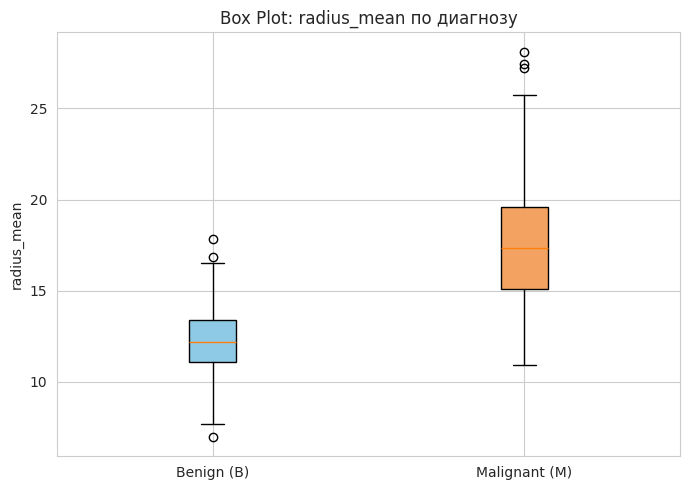

In [63]:
fig, ax = plt.subplots(figsize=(7, 5))
data_by_group = [df.loc[df['diagnosis'] == g, 'radius_mean'] for g in ['B', 'M']]
bp = ax.boxplot(data_by_group, labels=['Benign (B)', 'Malignant (M)'], patch_artist=True)
for patch, color in zip(bp['boxes'], ['#8ecae6', '#f4a261']):
    patch.set_facecolor(color)
ax.set_title('Box Plot: radius_mean по диагнозу')
ax.set_ylabel('radius_mean')
plt.tight_layout()
plt.show()

**Комментарий:** ящики почти не перекрываются — у группы Malignant (M) медиана
(≈17.33) заметно выше, чем у Benign (B) (≈12.20), а сам ящик группы M шире (больше разброс,
std ≈ 3.20 против 1.78 у B). Это визуально подтверждает гипотезу H2: злокачественные опухоли
в среднем крупнее и более разнородны по размеру ядра, чем доброкачественные.

**Промпт:**
«Построй ECDF `radius_mean` отдельно для каждой группы диагноза на одном графике, чтобы
сравнить не только медианы, но и форму распределений целиком.»

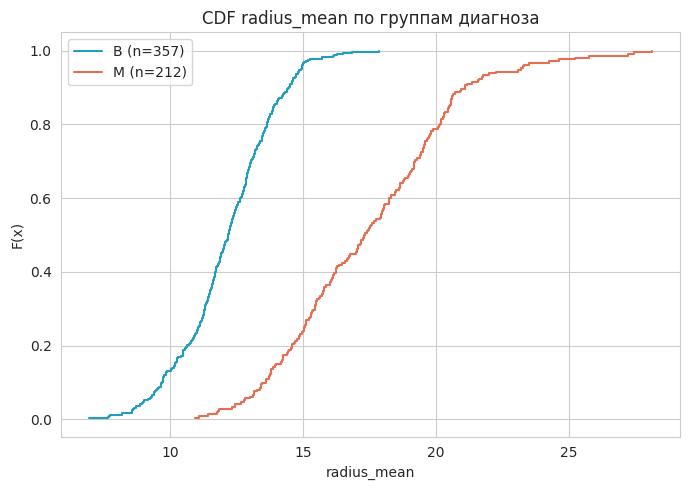

In [64]:
fig, ax = plt.subplots(figsize=(7, 5))
for g, color in zip(['B', 'M'], ['#219ebc', '#e76f51']):
    vals = np.sort(df.loc[df['diagnosis'] == g, 'radius_mean'].values)
    y = np.arange(1, len(vals) + 1) / len(vals)
    ax.plot(vals, y, drawstyle='steps-post', color=color, label=f'{g} (n={len(vals)})')

ax.set_title('CDF radius_mean по группам диагноза')
ax.set_xlabel('radius_mean')
ax.set_ylabel('F(x)')
ax.legend()
plt.tight_layout()
plt.show()

**Комментарий:** кривая CDF группы M целиком сдвинута вправо относительно кривой
группы B и заметно более пологая — то есть при любом фиксированном значении радиуса доля
злокачественных образцов с ≤ этим значением меньше, чем доля доброкачественных. Пересечения
кривых почти нет, что говорит о хорошей разделяющей способности этого признака.

In [65]:
group_stats = df.groupby('diagnosis')['radius_mean'].agg(
    mean='mean', median='median', std='std',
    q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75)
)
group_stats['IQR'] = group_stats['q3'] - group_stats['q1']
display(group_stats.round(3))

# доля выбросов (по общему правилу 1.5*IQR из части 4), приходящаяся на каждый класс
outlier_mask = (df['radius_mean'] < low_b) | (df['radius_mean'] > high_b)
print('\nРаспределение выбросов radius_mean по диагнозу:')
print(df.loc[outlier_mask, 'diagnosis'].value_counts())

,mean,median,std,q1,q3,IQR
diagnosis,,,,,,
B,12.147,12.200,1.781,11.080,13.37,2.290
M,17.463,17.325,3.204,15.075,19.59,4.515



Распределение выбросов radius_mean по диагнозу:
diagnosis
M    14
Name: count, dtype: int64


**Комментарий (сравнение медиан и разброса, проверка гипотезы H4):** медиана
`radius_mean` у M (17.33) на ~42% больше, чем у B (12.20), а стандартное отклонение у M
почти в 1.8 раза больше (3.20 против 1.78) — злокачественные опухоли не только крупнее, но и
разнороднее по размеру. Все 14 выбросов, найденных в части 4 по правилу 1.5×IQR, при разбивке
по группам оказываются образцами класса **Malignant** — гипотеза H4 подтверждается: аномально
крупные значения радиуса — это не случайный шум, а системная характеристика злокачественных
образцов, и удалять их из выборки перед моделированием было бы ошибкой.

### Итоговые выводы по разведочному анализу

- Данные полны (пропусков в содержательных признаках нет), дубликатов нет, все 30 признаков —
  количественные шкалы отношений, целевая переменная `diagnosis` — бинарная категориальная.
- Большинство признаков распределены с правосторонней асимметрией и не проходят строгую
  проверку на нормальность (4-Plot) — для дальнейшего моделирования предпочтительны
  устойчивые к выбросам методы масштабирования (Robust Scaling) и метрики (медиана, IQR).
- `radius_mean`, `perimeter_mean`, `area_mean` практически дублируют друг друга (r > 0.98) —
  кандидаты на объединение/отбор признаков.
- `radius_mean` и признаки вогнутости контура — сильные кандидаты-предикторы для задачи
  классификации диагноза, `texture_mean` — слабый предиктор.
- Выбросы по размеру ядра не случайны и почти полностью относятся к классу Malignant —
  это содержательный сигнал, а не измерительный шум, удалять их не следует.
- Гипотезы H1–H4 сформулированы в части 5 и подтверждены в части 6; они задают направление
  для последующего построения модели классификации (например, логистической регрессии —
  см. лекцию 1) и для более глубокой предобработки (лекция 3).